# ДЗ 8. Графики для менеджера: Matplotlib и Seaborn
Срок: **до воскресенья 29.11, 24:00**.
Сдача: папка `hw08` репозитория `dsa-homework` (`hw08.ipynb`): `git add hw08` → `git commit` → `git push`, ссылку прикрепите в LMS. Перед сдачей запустите все ячейки, чтобы графики были видны в GitHub.

Каждый график: **заголовок-вывод, подписи осей с единицами, рядом число, которым проверен заголовок**. Под графиком – вывод для менеджера (в print или Markdown-ячейке): что видно и что делать.

Инструменты: всё с уроков 1–8. Если берёте непройденный инструмент, объясните его в комментарии.

- **[База]** обязательно для всех · **[Стандарт]** сколько получится · **[Челлендж]** для тех, кому легко.

## [Для всех] Чтение кода: без запуска
Сначала напишите ответ и «почему», потом запустите.
```python
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
# 1
fig, ax = plt.subplots()
pd.Series([3, 1, 2], index=["a", "b", "c"]).sort_values().plot(kind="bar", ax=ax)
print([t.get_text() for t in ax.get_xticklabels()])
# 2
fig, axes = plt.subplots(1, 3)
print(axes.shape)
# 3
fig, ax = plt.subplots()
sns.barplot(x=["a", "a", "b"], y=[10, 30, 5], ax=ax)
print([float(b.get_height()) for b in ax.patches])
# 4
counts, edges = np.histogram([10, 20, 30, 40], bins=2)
print(counts, edges)
# 5
fig, (a1, a2) = plt.subplots(1, 2)
a1.plot([1, 2], [95, 100])
a2.bar([1, 2], [95, 100])
print(a1.get_ylim()[0] > 0, a2.get_ylim()[0])
```

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

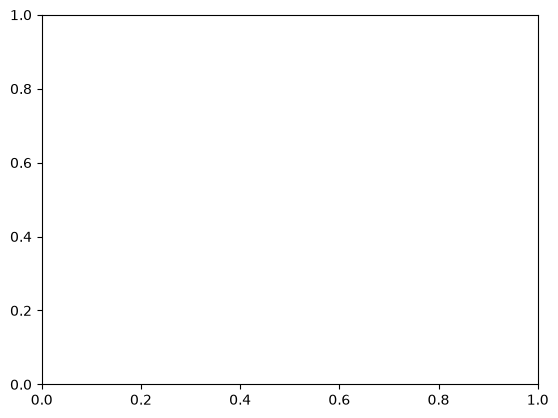

In [22]:
fig, ax = plt.subplots()

In [23]:
pd.Series([3, 1, 2], index=["b", "c", "a"]).sort_values()

c    1
a    2
b    3
dtype: int64

In [24]:
pd.Series([3, 1, 2], index=["a", "b", "c"]).sort_values().plot(kind="bar", ax=ax)
print([t.get_text() for t in ax.get_xticklabels()])

['b', 'c', 'a']


Ваши ответы и объяснения:

1. 
2. 
3. 
4. 
5. 

In [25]:
# Загрузка orders.csv: в Colab нажмите «Выбрать файлы» и укажите orders.csv из LMS.
# Если файл уже лежит рядом с ноутбуком, загрузка пропускается.
import os
if not os.path.exists("orders.csv"):
    try:
        from google.colab import files
        files.upload()
    except ImportError:
        print("Положите orders.csv в одну папку с ноутбуком")
print("orders.csv на месте:", os.path.exists("orders.csv"))

orders.csv на месте: True


In [26]:
# Очистка урока 6 одной ячейкой: суммы, города, дубли, даты, TEST
import pandas as pd
import numpy as np

CITY = {"алматы": "Алматы", "almaty": "Алматы", "астана": "Астана", "astana": "Астана",
        "шымкент": "Шымкент", "shymkent": "Шымкент", "караганда": "Караганда",
        "актобе": "Актобе", "атырау": "Атырау"}

df = pd.read_csv("orders.csv")
df["amount"] = pd.to_numeric(df["amount"].str.replace(" ", ""))
df["city"] = df["city"].str.strip().str.lower().map(CITY)
df = df.drop_duplicates()
df["order_date"] = pd.to_datetime(df["order_date"])
df["month"] = df["order_date"].dt.month
df = df[df["customer_id"] != "TEST"].copy()    # copy: дальше добавим столбцы
df.shape

(5280, 9)

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

df["cancel"] = df["status"] == "отменён"     # True/False, урок 7
paid = df[df["status"] == "оплачен"]
len(paid)

4739

Можно вместо ячейки очистки взять свою функцию `clean()` из ДЗ 6. Проверка: 5 280 строк, 4 739 оплаченных.

## [База] 1. Дни недели
В ДЗ 6 меньше всего заказов было в понедельник. Нарисуйте число заказов по дням недели столбиками **в порядке пн → вс** с подписями «пн», «вт», … (подсказка: `.dt.day_of_week` даёт 0 для понедельника, `value_counts().sort_index()`).
Проверьте высоты столбиков (`ax.patches`) против таблицы. Почему `value_counts()` без `sort_index()` здесь не подходит?

<Axes.ArtistList of 3 patches>


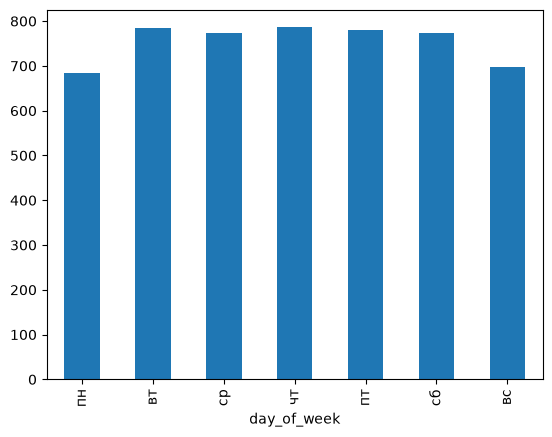

In [50]:
# 1
df['day_of_week'] = df['order_date'].dt.day_of_week
weekdays = {0: "пн", 1: "вт", 2: "ср", 3: "чт",
        4: "пт", 5: "сб", 6: "вс"}

day_of_week_count = df['day_of_week'].value_counts().sort_index()

day_of_week_count.index = day_of_week_count.index.map(weekdays)

day_of_week_count.plot(kind="bar")      # Pandas рисует таблицу через Matplotlib одной строкой
print(ax.patches)
plt.show()


Потому что в задании нужна сортировка с 0.

## [База] 2. Категории: сентябрь и октябрь
Выручка оплаченных по категориям и месяцам (`pivot_table`, урок 7). Два графика рядом (`plt.subplots(1, 2)`): слева выручка сентября и октября столбиками (`pc[[9, 10]].plot(kind="barh", ax=axes[0])`), справа изменение в %, отсортировано, самая падающая категория цветом.
Какая категория падает сильнее всех? Сходится с ДЗ 4 и ДЗ 7?

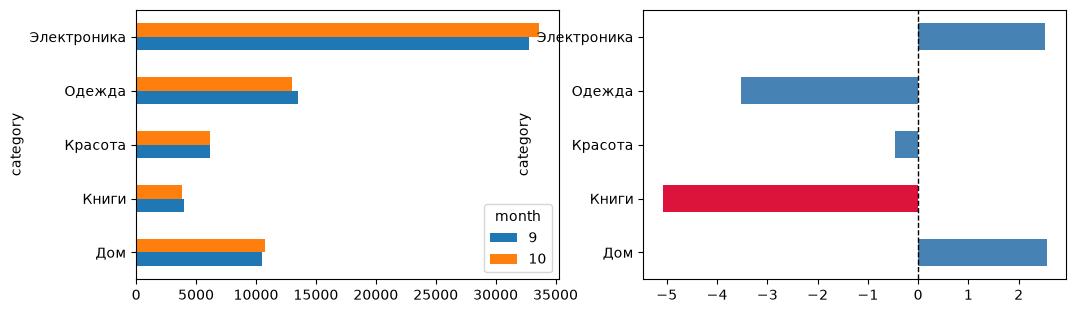

In [66]:
# 2
pc = paid.pivot_table(index="category", columns="month", values="amount", aggfunc="mean").round(3)
pc['chg'] = (pc[10] - pc[9])/ pc[9] * 100

min_val = pc['chg'].min()
colors = ['crimson' if val == min_val else 'steelblue' for val in pc['chg']]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
pc[[9, 10]].plot(kind="barh", ax=axes[0])

pc['chg'].plot(kind="barh", ax=axes[1], color=colors)
axes[1].axvline(0, color='black', linestyle='--', linewidth=1)

## [База] 3. Выручка компании по дням
Выручка оплаченных по дням линией (`groupby` по `.dt.date`). Отметьте 1 октября вертикальной линией (`ax.axvline`). Найдите день с минимальной и максимальной выручкой.
Видно ли на этом графике падение на 2,3%? Сравните разброс выручки по дням (`std`) с разницей средних за день в сентябре и октябре.

In [ ]:
# 3


## [Стандарт] 4. Исправьте код от AI
AI нарисовал график и пишет менеджеру: «Выручка в Шымкенте отстаёт от Алматы в разы».
```python
sns.barplot(data=df, x="city", y="amount")
plt.ylim(13500, 15500)
plt.title("Выручка по городам: Шымкент отстаёт в разы")
plt.show()
```
В коде **три** ошибки. Найдите их (проверьте высоты столбиков через `ax.patches`), нарисуйте правильный график выручки и напишите менеджеру, что на самом деле отличает Шымкент: уровень выручки или её изменение?

In [ ]:
# 4

## [Стандарт] 5. Город или срок доставки?
Тепловая карта «город × срок доставки»: доля отмен (`annot=True`, `fmt=".0%"`). Рядом вторая тепловая карта: число заказов в каждой клетке (`fmt=".0f"`).
Отменяют ли в Шымкенте чаще, чем в других городах, **при одинаковом сроке доставки**? Посчитайте долю отмен в Шымкенте и в остальных городах только для заказов со сроком ≤ 3 дня. Что это значит для решения менеджера?

In [ ]:
# 5

## [Стандарт] 6. Выбросы на ящике с усами
Ящик с усами: чек оплаченных по категориям. Посчитайте, сколько точек-выбросов в каждой категории по правилу 1,5 IQR (`groupby("category")["amount"].quantile(0.25)` и `0.75`).
В ДЗ 5 одна граница на всех (около 38 тыс. ₸) записала в выбросы почти только Электронику. Сколько выбросов теперь и в каких категориях? Какой подход честнее и почему?

In [ ]:
# 6

## [Челлендж] 7. Две оси от AI
AI нарисовал по Шымкенту заказы в день и выручку в день на двух осях (`ax.twinx()`) и пишет: «Линии идут вместе, всё в порядке». Две оси позволяют подогнать любые две линии друг к другу.
Нарисуйте честно, на одной оси: число заказов в день и выручку оплаченных в день в Шымкенте, обе как **индекс к среднему дню сентября = 100**. Какой индекс у каждой линии в среднем за октябрь? Что это говорит об отменах?

In [ ]:
# 7

## [Челлендж] 8. Plotly: найти момент сбоя
Точечный график заказов Шымкента 28.09–03.10: `px.scatter(x="order_date", y="delivery_days", color="status", hover_data=["order_id"])`. Наведением найдите последний заказ с быстрой доставкой (≤ 3 дня) и первый медленный (≥ 5 дней).
Проверьте ответ кодом Pandas (фильтр и `sort_values`). GitHub не покажет график Plotly, поэтому ответ напишите текстом.

In [ ]:
# 8